In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print(os.listdir("../Dataset"))

FileNotFoundError: [WinError 3] The system cannot find the path specified: '../Dataset'

In [2]:
import os
print(os.getcwd())
print(os.listdir("."))

c:\Users\Aaryan\OneDrive\Desktop\HR_Analytics_Attrition
['Dataset', 'HR_Attrition_Analysis.ipynb', 'PowerBI', 'Python', 'README.md', 'Screenshots', 'SQL']


In [3]:
print(os.listdir("Dataset"))

['WA_Fn-UseC_-HR-Employee-Attrition.csv']


In [4]:
df = pd.read_csv("Dataset/WA_Fn-UseC_-HR-Employee-Attrition.csv")
print(df.shape)
df.head()

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [5]:
print(df.shape)

(1470, 35)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [7]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [8]:
df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [9]:
df["Attrition"].value_counts(normalize=True) * 100

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64

In [10]:
# Check which columns have only one unique value
df.nunique().sort_values().head(6)

EmployeeCount        1
Over18               1
StandardHours        1
Attrition            2
OverTime             2
PerformanceRating    2
dtype: int64

In [11]:
# Make a cleaned copy, keeping the original df untouched
df_clean = df.drop(columns=["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"])
print(df_clean.shape)

(1470, 31)


In [12]:
# Convert Attrition from Yes/No to 1/0 (models need numbers)
df_clean["Attrition"] = df_clean["Attrition"].map({"Yes": 1, "No": 0})
df_clean["Attrition"].value_counts()

Attrition
0    1233
1     237
Name: count, dtype: int64

In [13]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

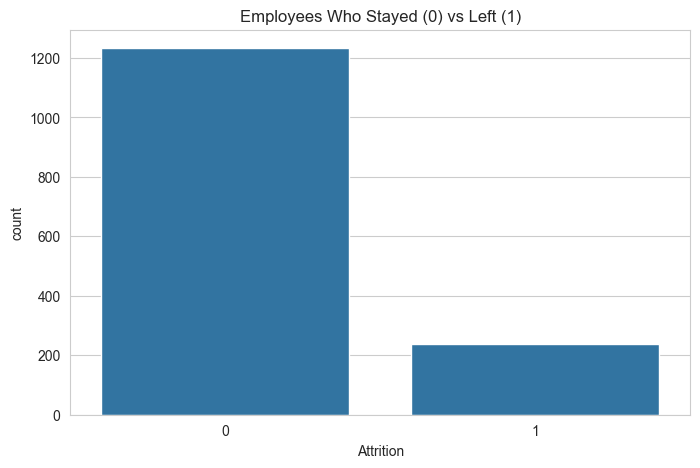

In [14]:
sns.countplot(x="Attrition", data=df_clean)
plt.title("Employees Who Stayed (0) vs Left (1)")
plt.show()

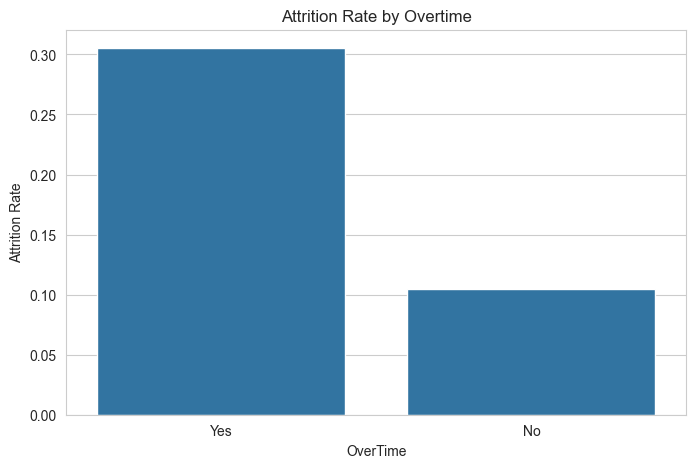

In [15]:
sns.barplot(x="OverTime", y="Attrition", data=df_clean, errorbar=None)
plt.title("Attrition Rate by Overtime")
plt.ylabel("Attrition Rate")
plt.show()

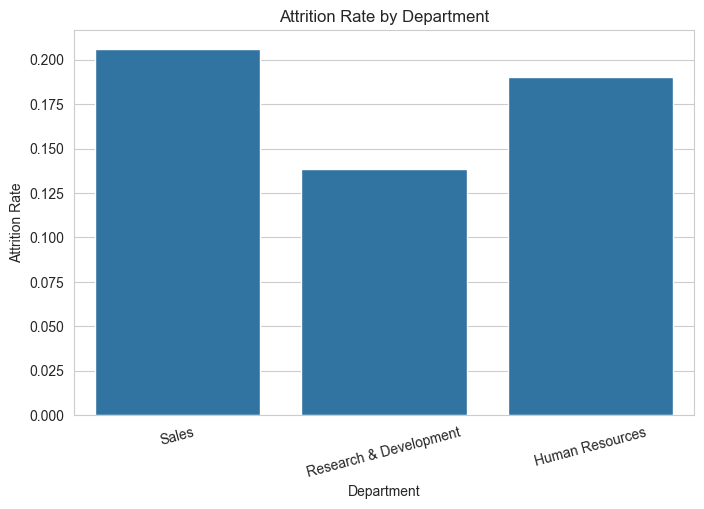

In [16]:
sns.barplot(x="Department", y="Attrition", data=df_clean, errorbar=None)
plt.title("Attrition Rate by Department")
plt.ylabel("Attrition Rate")
plt.xticks(rotation=15)
plt.show()

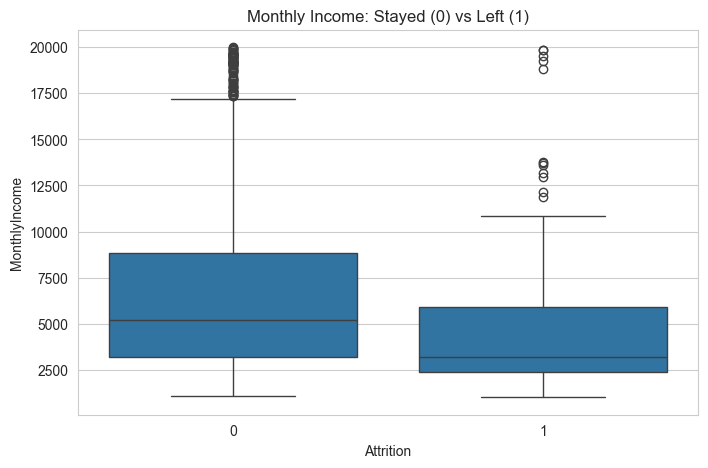

In [17]:
sns.boxplot(x="Attrition", y="MonthlyIncome", data=df_clean)
plt.title("Monthly Income: Stayed (0) vs Left (1)")
plt.show()

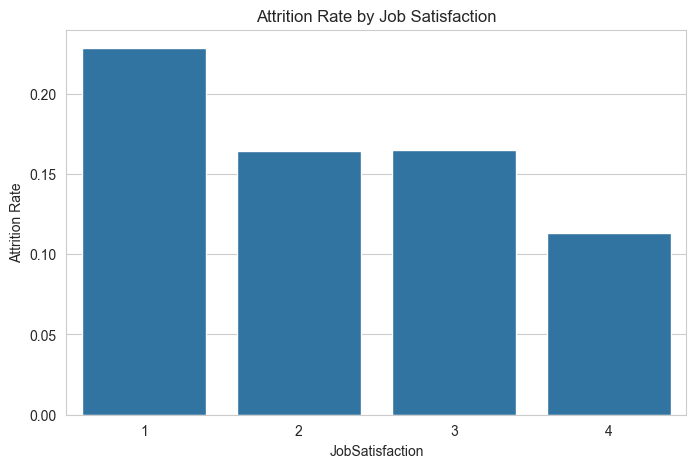

In [18]:
sns.barplot(x="JobSatisfaction", y="Attrition", data=df_clean, errorbar=None)
plt.title("Attrition Rate by Job Satisfaction")
plt.ylabel("Attrition Rate")
plt.show()

In [19]:
df_clean.groupby("Attrition")["MonthlyIncome"].agg(["count", "mean", "median"])

,count,mean,median
Attrition,,,
0,1233,6832.739659,5204.0
1,237,4787.092827,3202.0


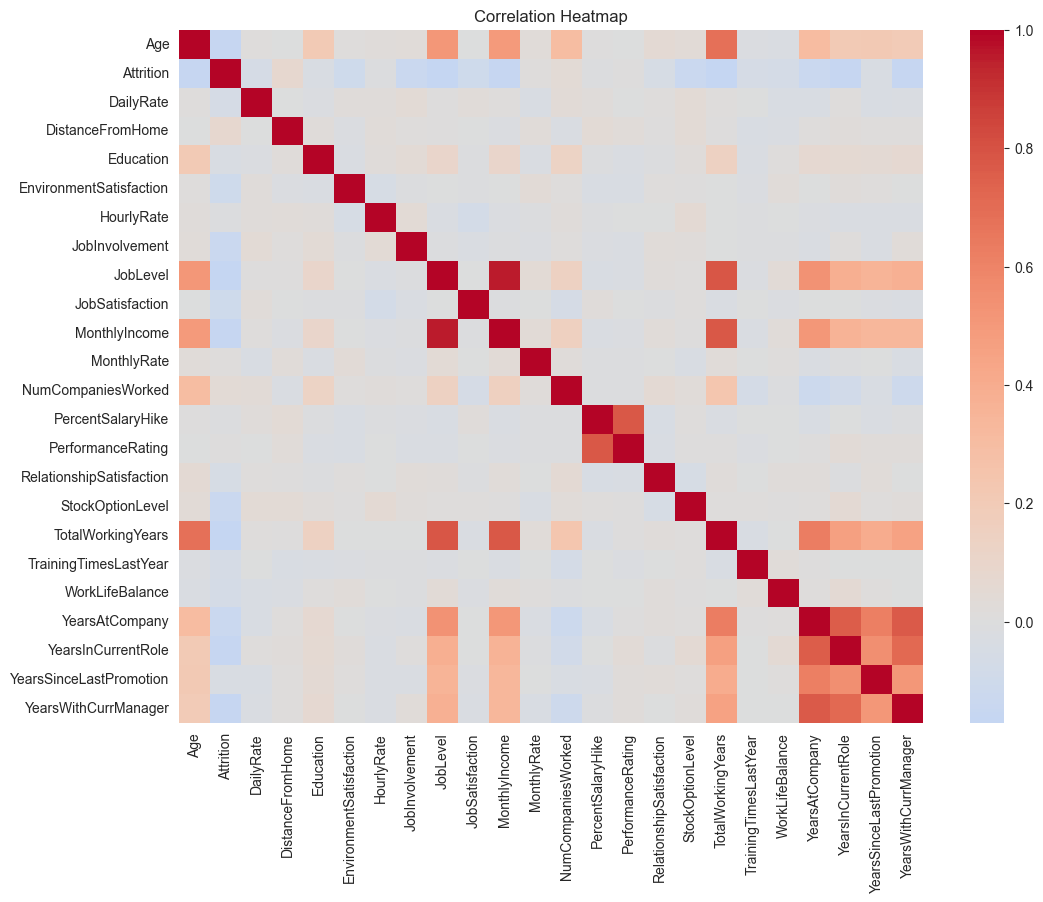

In [20]:
plt.figure(figsize=(12, 9))
corr = df_clean.select_dtypes(include="number").corr()
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

In [21]:
corr["Attrition"].sort_values()

TotalWorkingYears          -0.171063
JobLevel                   -0.169105
YearsInCurrentRole         -0.160545
MonthlyIncome              -0.159840
Age                        -0.159205
YearsWithCurrManager       -0.156199
StockOptionLevel           -0.137145
YearsAtCompany             -0.134392
JobInvolvement             -0.130016
JobSatisfaction            -0.103481
EnvironmentSatisfaction    -0.103369
WorkLifeBalance            -0.063939
TrainingTimesLastYear      -0.059478
DailyRate                  -0.056652
RelationshipSatisfaction   -0.045872
YearsSinceLastPromotion    -0.033019
Education                  -0.031373
PercentSalaryHike          -0.013478
HourlyRate                 -0.006846
PerformanceRating           0.002889
MonthlyRate                 0.015170
NumCompaniesWorked          0.043494
DistanceFromHome            0.077924
Attrition                   1.000000
Name: Attrition, dtype: float64

In [22]:
df_model = pd.get_dummies(df_clean, drop_first=True)
print(df_model.shape)

(1470, 45)


In [23]:
X = df_model.drop("Attrition", axis=1)
y = df_model["Attrition"]
print(X.shape, y.shape)

(1470, 44) (1470,)


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(1176, 44) (294, 44)


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
log_model = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, log_pred))
print(confusion_matrix(y_test, log_pred))
print(classification_report(y_test, log_pred))

Accuracy: 0.7517006802721088
[[192  55]
 [ 18  29]]
              precision    recall  f1-score   support

           0       0.91      0.78      0.84       247
           1       0.35      0.62      0.44        47

    accuracy                           0.75       294
   macro avg       0.63      0.70      0.64       294
weighted avg       0.82      0.75      0.78       294



In [27]:
from sklearn.metrics import roc_auc_score

log_proba = log_model.predict_proba(X_test_scaled)[:, 1]
print("Logistic ROC-AUC:", roc_auc_score(y_test, log_proba))

Logistic ROC-AUC: 0.7982599707123783


In [28]:
coef = pd.Series(log_model.coef_[0], index=X.columns).sort_values()
print(coef.head(8))   # strongest push toward staying
print(coef.tail(8))   # strongest push toward leaving

TotalWorkingYears              -0.660270
EducationField_Life Sciences   -0.512319
YearsWithCurrManager           -0.461322
EducationField_Medical         -0.452134
EnvironmentSatisfaction        -0.434370
JobSatisfaction                -0.393219
EducationField_Other           -0.389932
JobRole_Research Director      -0.388326
dtype: float64
Department_Sales                    0.470587
YearsSinceLastPromotion             0.499063
BusinessTravel_Travel_Rarely        0.512780
JobRole_Sales Representative        0.531090
JobLevel                            0.650173
BusinessTravel_Travel_Frequently    0.722538
OverTime_Yes                        0.771095
JobRole_Laboratory Technician       0.810172
dtype: float64


In [29]:
rf_proba = rf_model.predict_proba(X_test)[:, 1]
print("Random Forest ROC-AUC:", roc_auc_score(y_test, rf_proba))

NameError: name 'rf_model' is not defined

In [30]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, rf_pred))
print(confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

Accuracy: 0.8231292517006803
[[229  18]
 [ 34  13]]
              precision    recall  f1-score   support

           0       0.87      0.93      0.90       247
           1       0.42      0.28      0.33        47

    accuracy                           0.82       294
   macro avg       0.65      0.60      0.62       294
weighted avg       0.80      0.82      0.81       294



In [31]:
rf_proba = rf_model.predict_proba(X_test)[:, 1]
print("Random Forest ROC-AUC:", roc_auc_score(y_test, rf_proba))

Random Forest ROC-AUC: 0.777586355413903


In [32]:
from sklearn.metrics import roc_auc_score

log_proba = log_model.predict_proba(X_test_scaled)[:, 1]
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("Logistic ROC-AUC:", roc_auc_score(y_test, log_proba))
print("Random Forest ROC-AUC:", roc_auc_score(y_test, rf_proba))

Logistic ROC-AUC: 0.7982599707123783
Random Forest ROC-AUC: 0.777586355413903


In [33]:
coef = pd.Series(log_model.coef_[0], index=X.columns).sort_values()
print(coef.head(8))   # strongest push toward staying
print(coef.tail(8))   # strongest push toward leaving

TotalWorkingYears              -0.660270
EducationField_Life Sciences   -0.512319
YearsWithCurrManager           -0.461322
EducationField_Medical         -0.452134
EnvironmentSatisfaction        -0.434370
JobSatisfaction                -0.393219
EducationField_Other           -0.389932
JobRole_Research Director      -0.388326
dtype: float64
Department_Sales                    0.470587
YearsSinceLastPromotion             0.499063
BusinessTravel_Travel_Rarely        0.512780
JobRole_Sales Representative        0.531090
JobLevel                            0.650173
BusinessTravel_Travel_Frequently    0.722538
OverTime_Yes                        0.771095
JobRole_Laboratory Technician       0.810172
dtype: float64


MonthlyIncome           0.075518
Age                     0.061215
TotalWorkingYears       0.051915
DailyRate               0.050251
YearsAtCompany          0.049284
OverTime_Yes            0.045947
MonthlyRate             0.045809
HourlyRate              0.043147
DistanceFromHome        0.042797
YearsWithCurrManager    0.042588
dtype: float64


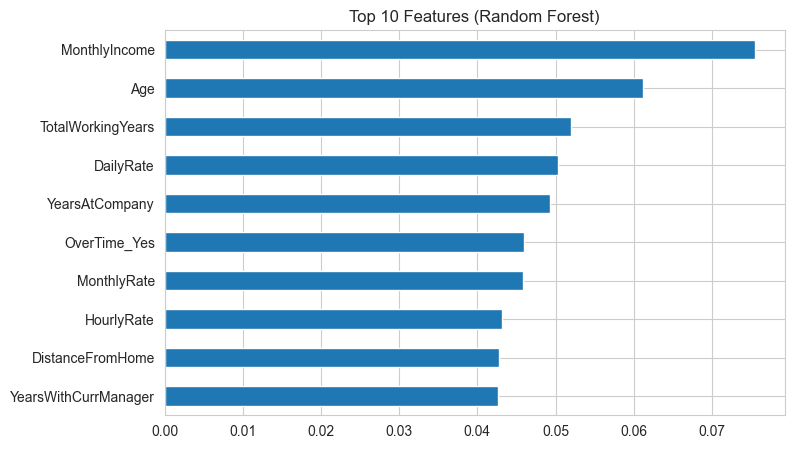

In [34]:
imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(10))

imp.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Features (Random Forest)")
plt.show()

In [35]:
X_all_scaled = scaler.transform(X)

df_out = df.copy()
df_out["AttritionRiskScore"] = log_model.predict_proba(X_all_scaled)[:, 1].round(3)
df_out["RiskLevel"] = pd.cut(
    df_out["AttritionRiskScore"],
    bins=[0, 0.3, 0.6, 1.0],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

df_out.to_csv("Dataset/HR_Attrition_Predictions.csv", index=False)
print(df_out[["Attrition", "AttritionRiskScore", "RiskLevel"]].head())
print(df_out["RiskLevel"].value_counts())

  Attrition  AttritionRiskScore RiskLevel
0       Yes               0.903      High
1        No               0.113       Low
2       Yes               0.724      High
3        No               0.370    Medium
4        No               0.835      High
RiskLevel
Low       768
Medium    361
High      341
Name: count, dtype: int64
